In [8]:
# Step 1: Import Libraries
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, roc_curve
import matplotlib.pyplot as plt
import seaborn as sns

   customerID  gender  SeniorCitizen Partner Dependents  tenure PhoneService  \
0  7590-VHVEG  Female              0     Yes         No       1           No   
1  5575-GNVDE    Male              0      No         No      34          Yes   
2  3668-QPYBK    Male              0      No         No       2          Yes   
3  7795-CFOCW    Male              0      No         No      45           No   
4  9237-HQITU  Female              0      No         No       2          Yes   

      MultipleLines InternetService OnlineSecurity  ... DeviceProtection  \
0  No phone service             DSL             No  ...               No   
1                No             DSL            Yes  ...              Yes   
2                No             DSL            Yes  ...               No   
3  No phone service             DSL            Yes  ...              Yes   
4                No     Fiber optic             No  ...               No   

  TechSupport StreamingTV StreamingMovies        Contract Pape

/tmp/ipykernel_19720/2705463663.py:16: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  data['TotalCharges'].fillna(data['TotalCharges'].median(), inplace=True)


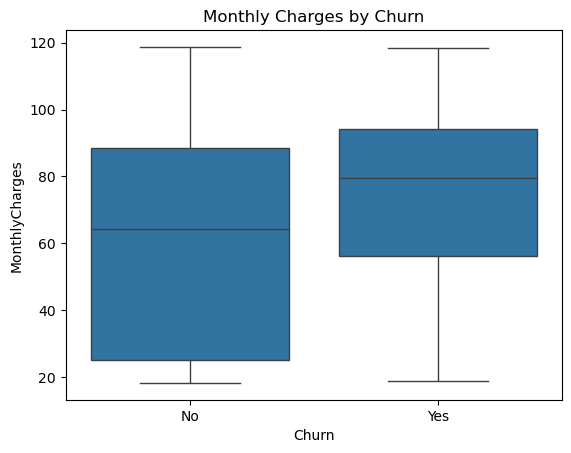

In [9]:
# Step 2: Load and Explore the Dataset
# Load dataset (replace 'Telco-Customer-Churn.csv' with the actual file path)
data = pd.read_csv('Telco-Customer-Churn.csv')


# View the first few rows
print(data.head())


# Check for missing values
print(data.isnull().sum())


# TotalCharges might have missing or erroneous entries; handle them
data['TotalCharges'] = pd.to_numeric(data['TotalCharges'], errors='coerce')
data['TotalCharges'].fillna(data['TotalCharges'].median(), inplace=True)


# Optional: Visualize relationships (e.g., MonthlyCharges vs. Churn)
sns.boxplot(x='Churn', y='MonthlyCharges', data=data)
plt.title("Monthly Charges by Churn")
plt.show()

In [10]:
# Step 3: Preprocess the Data
# Drop customerID as it's not useful for modeling
data = data.drop(columns=['customerID'])


# Encode categorical variables
data = pd.get_dummies(data, drop_first=True)


# Separate features and target variable
X = data.drop(columns=['Churn_Yes'])  # 'Churn_Yes' is 1 for churners, 0 for non-churners
y = data['Churn_Yes']


# Standardize numerical features
scaler = StandardScaler()
numerical_features = ['tenure', 'MonthlyCharges', 'TotalCharges']
X[numerical_features] = scaler.fit_transform(X[numerical_features])

In [11]:
# Step 4: Split the Data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [13]:
# Step 5: Train the SVM Model
# Initialize the SVM classifier with an RBF kernel
svc_model = SVC(kernel='rbf', C=1, probability=True)


# Train the model
svc_model.fit(X_train, y_train)

SVC(C=1, probability=True)

Confusion Matrix:
[[953  83]
 [179 194]]

Classification Report:
              precision    recall  f1-score   support

       False       0.84      0.92      0.88      1036
        True       0.70      0.52      0.60       373

    accuracy                           0.81      1409
   macro avg       0.77      0.72      0.74      1409
weighted avg       0.80      0.81      0.80      1409



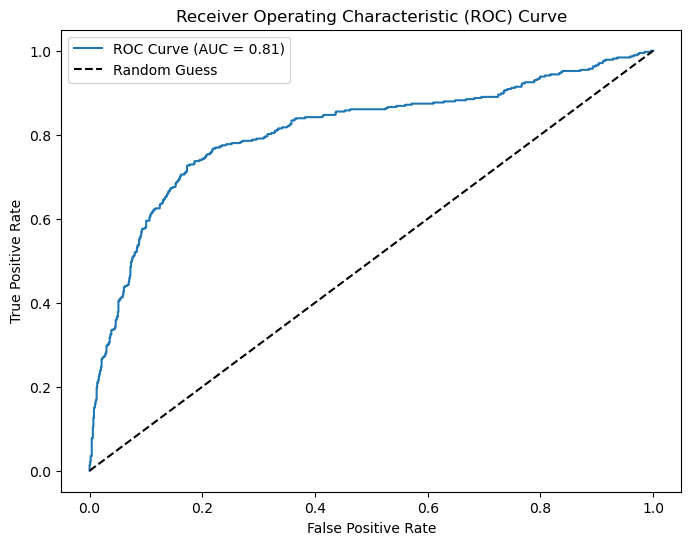

In [14]:
# Step 6: Evaluate the Model
# Predict on the test data
y_pred = svc_model.predict(X_test)


# Classification report and confusion matrix
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))


print("\nClassification Report:")
print(classification_report(y_test, y_pred))


# ROC Curve and AUC
y_prob = svc_model.predict_proba(X_test)[:, 1]
roc_auc = roc_auc_score(y_test, y_prob)


fpr, tpr, thresholds = roc_curve(y_test, y_prob)
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, label=f'ROC Curve (AUC = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], 'k--', label='Random Guess')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curve')
plt.legend()
plt.show()

In [15]:
# Step 7: Optimize the Model
# Hyperparameter tuning with GridSearchCV
param_grid = {
    'C': [0.1, 1, 10],
    'gamma': [1, 0.1, 0.01, 0.001],
    'kernel': ['rbf']
}


grid_search = GridSearchCV(SVC(probability=True), param_grid, cv=5, scoring='roc_auc')
grid_search.fit(X_train, y_train)


# Print the best parameters
print("Best Parameters:", grid_search.best_params_)


# Train the optimized model
optimized_model = grid_search.best_estimator_
optimized_model.fit(X_train, y_train)


# Evaluate the optimized model
y_pred_optimized = optimized_model.predict(X_test)
print("\nOptimized Model Classification Report:")
print(classification_report(y_test, y_pred_optimized))


# Recalculate ROC Curve for the optimized model
y_prob_optimized = optimized_model.predict_proba(X_test)[:, 1]
roc_auc_optimized = roc_auc_score(y_test, y_prob_optimized)


fpr_optimized, tpr_optimized, thresholds_optimized = roc_curve(y_test, y_prob_optimized)
plt.figure(figsize=(8, 6))
plt.plot(fpr_optimized, tpr_optimized, label=f'Optimized ROC Curve (AUC = {roc_auc_optimized:.2f})')
plt.plot([0, 1], [0, 1], 'k--', label='Random Guess')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Optimized Receiver Operating Characteristic (ROC) Curve')
plt.legend()
plt.show()

KeyboardInterrupt: 